In [1]:
# import os
# import sys
# # sys.path.insert(0, '/'.join(os.getcwd().split('/')[:-2]))

# from optical_volume import torch_geometry as Tgeometry
# from optical_volume import propagator
# from optical_volume import visualization
# from optical_volume import utils

# from py_wave_propagator import volume_prop as propagator

# from matplotlib import pyplot as plt

# import torch


import torch
import torchvision
from torchvision.transforms import GaussianBlur, Resize
import torchvision.transforms.functional as F

from optical_volume import optics
from optical_volume import scene
from optical_volume import utils

import numpy as np
from matplotlib import pyplot as plt

from plyfile import PlyData, PlyElement
import open3d as o3d
import trimesh

/home/syedkazim/anaconda3/envs/2026_optical_volume/lib/python3.9/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Convert ply mesh to voxel volume

In [2]:
plydata = PlyData.read('/home/syedkazim/sciebo - Kazim, Syed Muhammad (u491036@uni-siegen.de)@uni-siegen.sciebo.de/Lab/Projects/2026_[Ongoing]_Core_RI_Volume_Repo/OptiVolume/data/benchy.ply')

vertex = plydata["vertex"]

x  = vertex["x"]
y  = vertex["y"]
z  = vertex["z"]
nx = vertex["nx"]
ny = vertex["ny"]
nz = vertex["nz"]

points = np.column_stack((x, y, z))
normals = np.column_stack((nx, ny, nz))

print(points.shape)
print(normals.shape)

(112569, 3)
(112569, 3)


In [4]:
vertices = np.column_stack([
    vertex["x"],
    vertex["y"],
    vertex["z"]
]).astype(np.float64)

# Extract triangular faces
faces = np.vstack([
    face["vertex_indices"]
    for face in plydata["face"]
]).astype(np.int32)

print("Vertices:", vertices.shape)
print("Faces:", faces.shape)

Vertices: (112569, 3)
Faces: (225154, 3)


In [5]:
# # --------------------------------------------------
# # 2. Create Open3D triangle mesh
# # --------------------------------------------------

# mesh = o3d.geometry.TriangleMesh()

# mesh.vertices = o3d.utility.Vector3dVector(vertices)
# mesh.triangles = o3d.utility.Vector3iVector(faces)

# # Normals from PLY are not actually required for
# # voxelization. We can recompute them.
# mesh.compute_vertex_normals()

# print(mesh)

# # --------------------------------------------------
# # 3. Check mesh
# # --------------------------------------------------

# print("Watertight:",
#       mesh.is_watertight())

# print("Edge manifold:",
#       mesh.is_edge_manifold())

# print("Self intersecting:",
#       mesh.is_self_intersecting())

# print("Vertices:", len(mesh.vertices))
# print("Triangles:", len(mesh.triangles))

In [ ]:
mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    process=True
)

print(mesh)
print("Vertices:", len(mesh.vertices))
print("Faces:", len(mesh.faces))
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)

In [ ]:
# ============================================================
# 3. Voxelize the surface
# ============================================================
voxel_size = 0.25

voxels = mesh.voxelized(
    pitch=voxel_size
)

print("Voxel grid shape:", voxels.shape)

# ============================================================
# 4. Fill the interior
# ============================================================

filled = voxels.fill()

print("Filled voxel grid shape:", filled.shape)

In [ ]:
# ============================================================
# 5. Convert to NumPy
# ============================================================

volume = filled.matrix.astype(np.uint8)

print("Volume shape:", volume.shape)
print("Occupied voxels:", volume.sum())

# np.save("/home/syedkazim/sciebo - Kazim, Syed Muhammad (u491036@uni-siegen.de)@uni-siegen.sciebo.de/Lab/Projects/2026_[Ongoing]_Core_RI_Volume_Repo/OptiVolume/data/benchy.npy", volume)

(125, 193, 241)


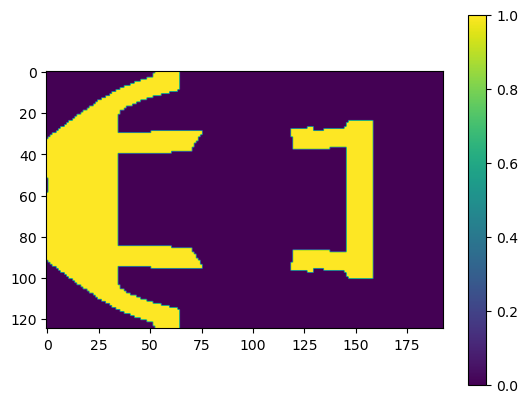

In [2]:
volume = np.load("/home/syedkazim/sciebo - Kazim, Syed Muhammad (u491036@uni-siegen.de)@uni-siegen.sciebo.de/Lab/Projects/2026_[Ongoing]_Core_RI_Volume_Repo/OptiVolume/data/benchy.npy")

print(volume.shape)

plt.imshow(volume[:, :, 100])
plt.colorbar()
plt.show()

In [6]:
visualization.visualize_grid_vol(volume, n_background=0, factor=2)

NameError: name 'visualization' is not defined

## CWFS measurement of the boat

In [3]:
voxel_volume = torch.zeros([500, 500, 500]).float()
voxel_volume[188:313, 150:343, 130:371] = torch.tensor(volume)

voxel_volume = voxel_volume*(0.03)+1.51

In [4]:
# example: functioning
WL = 500e-9
OBJ_SPACING = [1.5e-6, 1.5e-6, 1.5e-6]
SHAPE = [500, 500, 500]
NA = 0.4
DIST_PM_IM = 2.5e-3

TILE_LEN = 12e-6
PM_HEIGHT = 570e-9
PM_RI = 1.46
PM_SIG = 0.9

N_BG = 1.51
PAD = 512
FOC_PLANE_VAR = 0.1e-8

MAG = 4
OBJ_IMG_FACTOR = 2
EFF_MAG = int(4/2)

IMG_SPACING = [OBJ_SPACING[i]*OBJ_IMG_FACTOR for i in range(2)]
DIGITAL_PX = 3e-6
SUM_PATCH = int(DIGITAL_PX/IMG_SPACING[0])

DEVICE = 'cpu'


In [8]:
vol = scene.VoxelVolume(SHAPE, OBJ_SPACING, voxel_volume, n0=1.51, rotation_axis=[0, 1, 0], 
                        rotation_angle=45, object_center=([0.75e-6*500]*3))
grid = scene.volume.Grid(SHAPE, OBJ_SPACING)

In [9]:
vol_prop = optics.VolumePropagator(WL, OBJ_SPACING, N_BG)

lens = optics.F4ImagingSystem(WL, OBJ_SPACING, SHAPE, NA)
mag_obj = optics.utils.Magnification(torch.tensor(MAG/OBJ_IMG_FACTOR))
pm_obj = optics.BinaryPhaseMask(WL, TILE_LEN, IMG_SPACING, [x*EFF_MAG for x in SHAPE], PM_HEIGHT, PM_SIG, PM_RI)
px_int_obj = optics.utils.PixelIntegrator(SUM_PATCH)

prop_obj_space = optics.FreeSpacePropagator(WL/N_BG, OBJ_SPACING[:2], SHAPE[2]*OBJ_SPACING[2]/2 - FOC_PLANE_VAR, direction='backward', padding=PAD)
prop_img_space = optics.FreeSpacePropagator(WL, IMG_SPACING, DIST_PM_IM, direction='backward', padding=PAD)

cwfs_basic = optics.system.OpticalSystem((
        prop_obj_space, # centring + displacing focus plalne
        lens, # imaging the wavefield
        mag_obj, # magnified by MAG/OBJ_IMG_FACTOR
        prop_img_space, # prop to mask plane
        pm_obj, # applying the mask
        prop_img_space.set_direction('forward'), # prop to image plane
        px_int_obj # add complex values incident on each pixel patch
    ))

vol.to(DEVICE)
cwfs_basic.to(DEVICE)

exit_field = vol_prop.forward(vol.forward(grid.grid))



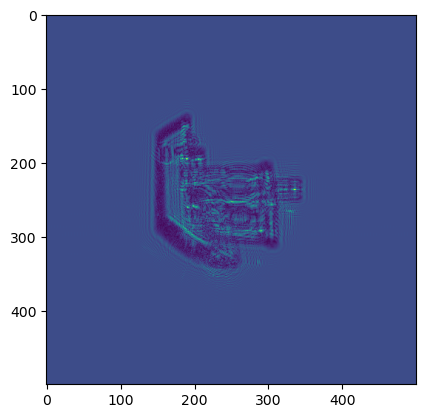

In [13]:
plt.imshow(exit_field.detach().abs())

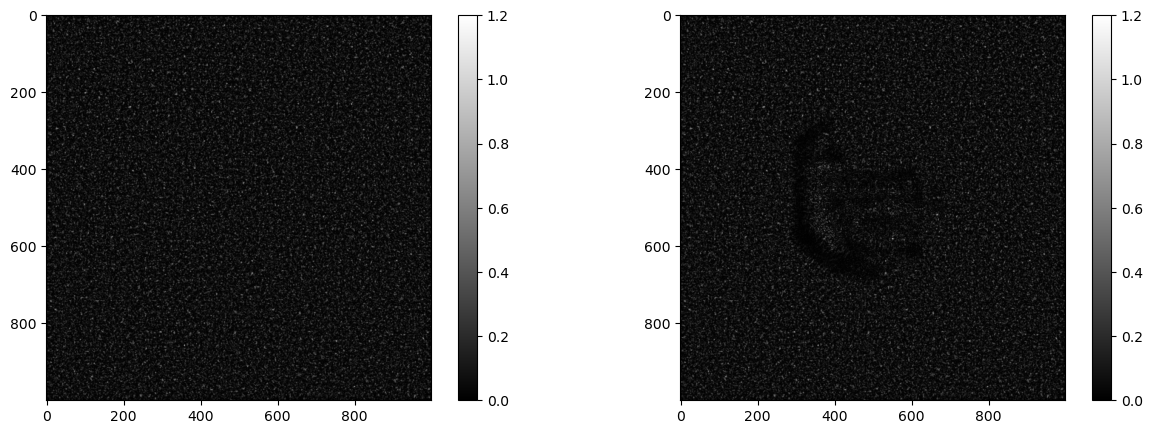

In [11]:
ref_field = cwfs_basic(torch.ones(SHAPE[:2]).type(torch.complex64).to(DEVICE))
cwfs_basic.fields.clear()
spn_field = cwfs_basic(exit_field.type(torch.complex64))

img_ref = ref_field.abs().detach().to('cpu')**2
img_spn = spn_field.abs().detach().to('cpu')**2

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

cm0 = axs[0].imshow(img_ref/img_ref.max(), cmap='gray', vmin=0, vmax=1.2)
plt.colorbar(cm0, ax=axs[0])

cm1 = axs[1].imshow(img_spn/img_ref.max(), cmap='gray', vmin=0, vmax=1.2)
plt.colorbar(cm1, ax=axs[1])

plt.show()

In [9]:
5e-3/200

2.5e-05